<a href="https://colab.research.google.com/github/aderemi1224/Guest_Sentiment/blob/main/05_sentiment_distilbert_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 - DistilBERT Sentiment Fine-Tuning

**What this notebook does**
1. Loads `data/processed/montra_cleaned_data.csv`
2. Encodes labels, splits the data and tokenizes with the DistilBERT multilingual tokenizer
3. Fine-tunes `distilbert-base-multilingual-cased` (3 epochs) with the Hugging Face `Trainer`
4. Evaluates, plots the confusion matrix and spot-checks real test reviews
5. Saves the model to `models/distilbert_sentiment` and the metrics to `models/distilbert_run_info.json`

**Needs:** output of notebook 02. A GPU is strongly recommended (or run on Colab). Training on CPU will be very slow.

**Next notebook:** `06_mlflow_dagshub_logging.ipynb`

In [1]:
! git clone https://github.com/aderemi1224/Guest_Sentiment.git
%cd Guest_Sentiment

Cloning into 'Guest_Sentiment'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 30 (delta 9), reused 16 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 2.86 MiB | 3.55 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/Guest_Sentiment


In [2]:
from pathlib import Path

# Paths are relative to the notebooks/ folder
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
from google.colab import files
uploaded = files.upload()

Saving montra_cleaned_data.csv to montra_cleaned_data.csv


In [4]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("CUDA available:", torch.cuda.is_available())

merged = pd.read_csv("montra_cleaned_data.csv")
X = merged["cleaned_review_text"].astype(str)
y = merged["sentiment_label"]

CUDA available: True


# Label Encoding and Dataset Splitting

Before training a machine learning model, the sentiment labels are converted from text into numerical values. A fixed label mapping is created so that **negative**, **neutral**, and **positive** always correspond to the same numerical values throughout the entire workflow. This ensures consistency when training the model and interpreting its predictions.

The labels are then encoded using this mapping, producing numerical labels that can be processed by the machine learning model. A reverse mapping is also created so that the numerical predictions can later be converted back into their original sentiment names.

The dataset is then divided into **training** and **testing** sets. In this case, 80% of the data is used for training while 20% is reserved for testing. The `random_state` ensures that the same split can be reproduced whenever the process is run again.

**Stratification** is used to maintain a similar proportion of negative, neutral, and positive reviews in both the training and testing sets. This is particularly important for classification tasks because it prevents one set from having a significantly different class distribution from the other.

Finally, the resulting datasets and labels are converted into lists, making them suitable for the subsequent model training process.

In [5]:
# Build a stable label mapping ONCE, use it everywhere
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}
y_encoded = y.map(label2id)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded   # keeps class balance consistent across splits
)

X_train = X_train.tolist()
X_test = X_test.tolist()
y_train = y_train.tolist()
y_test = y_test.tolist()

In [6]:
y_train[:10]

[2, 2, 0, 0, 0, 2, 2, 1, 1, 0]

# Loading the DistilBERT Tokenizer

A tokenizer is used to convert text into a format that a transformer model can understand. For this project, the **DistilBERT multilingual cased** model is used because it supports multiple languages while preserving the original letter casing of words.

The tokenizer associated with the selected model is loaded using the model name. Using the tokenizer that belongs to the same pretrained model ensures that the text is processed according to the vocabulary and tokenization method expected by the model.

For example, a hotel review such as *“The room was Excellent”* is converted from raw text into tokens and numerical representations that can later be passed to the DistilBERT model for sentiment classification.

In [7]:
from transformers import AutoTokenizer

model_name = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

In [8]:
text = "ShopEase is supercalifragilistic"
tokens = tokenizer.tokenize(text)

print(f"Original Sentence: {text}")
print(f"BERT's Lego Bricks: {tokens}")

Original Sentence: ShopEase is supercalifragilistic
BERT's Lego Bricks: ['Shop', '##E', '##ase', 'is', 'super', '##cali', '##fra', '##gil', '##istic']


In [9]:
ids = tokenizer.convert_tokens_to_ids(tokens)

for brick, brick_id in zip(tokens, ids):
    print(f"Brick: {brick:<12} | ID: {brick_id}")

Brick: Shop         | ID: 44132
Brick: ##E          | ID: 11259
Brick: ##ase        | ID: 16896
Brick: is           | ID: 10124
Brick: super        | ID: 25212
Brick: ##cali       | ID: 106407
Brick: ##fra        | ID: 31162
Brick: ##gil        | ID: 32837
Brick: ##istic      | ID: 29025


# Tokenizing the Training and Testing Text

The training and testing reviews are passed through the tokenizer to convert the raw text into numerical representations that the DistilBERT model can process.

**Truncation** ensures that reviews longer than 128 tokens are shortened, while **padding** adds extra tokens to shorter reviews so that all inputs have the same length. The `max_length=128` sets the maximum number of tokens allowed for each review.

The same tokenization process is applied separately to both the training and testing data. The resulting `train_encodings` contains the tokenized representation of the training reviews, including information such as the token IDs and attention masks required by the transformer model.

In simple terms, the process is:

**Raw Review → Tokenization → Token IDs + Attention Mask → DistilBERT Model**

In [10]:
train_encodings = tokenizer(X_train, truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(X_test, truncation=True, padding=True, max_length=128)
# train_encodings

# Creating the Sentiment Dataset

The tokenized text and corresponding sentiment labels are organized into a PyTorch dataset so they can be efficiently provided to the DistilBERT model during training and testing.

The `SentimentDataset` class connects each review's **tokenized representation** with its **sentiment label**. It also converts the tokenized values and labels into PyTorch tensors, which are the format required by the model.

Two separate datasets are created: one for the training data and another for the testing data. This allows the model to use the training dataset to learn sentiment patterns and the testing dataset to evaluate how well it performs on unseen reviews.

The overall structure is:

**Tokenized Reviews + Sentiment Labels → PyTorch Dataset → Model Training/Evaluation**

In [11]:
import torch

class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

train_dataset = SentimentDataset(train_encodings, y_train)
test_dataset = SentimentDataset(test_encodings, y_test)

# Loading the Pretrained DistilBERT Model

The pretrained **DistilBERT multilingual model** is loaded and configured for sentiment classification. Since the task has three sentiment classes—**negative, neutral, and positive**—the model is set with three output labels.

The `label2id` and `id2label` mappings are also provided to maintain consistency between the numerical labels and their corresponding sentiment names. This allows the model to associate each prediction with the correct sentiment category.

The model is therefore configured to take tokenized text as input and produce a prediction for one of the three sentiment classes.

**Input Review → DistilBERT → Sentiment Prediction (Negative / Neutral / Positive)**

In [12]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


# Configuring the Model Training

The `TrainingArguments` class is used to define how the DistilBERT model will be trained and evaluated.

The model is trained for **3 epochs**, with a batch size of **16** for training and **32** for evaluation. Evaluation and model saving are performed at the end of each epoch, allowing the model's performance to be monitored throughout training.

The training process logs information every 50 steps and keeps only the most recent saved checkpoint. The **best-performing model** is automatically loaded at the end of training based on **accuracy**.

Finally, reporting to external experiment-tracking services is disabled, allowing the training process to run without prompting for tools such as Weights & Biases.

Overall, these settings control the **training duration, batch sizes, evaluation frequency, checkpoint management, and selection of the best model**.

In [13]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none"             # prevents W&B prompt hijacking the run
)

# Defining Model Evaluation Metrics

The `compute_metrics` function defines the evaluation metrics used to measure the performance of the sentiment classification model.

During evaluation, the model produces prediction scores for each of the three sentiment classes. The class with the highest score is selected as the predicted sentiment. These predictions are then compared with the actual labels.

Two metrics are calculated:

* **Accuracy** measures the proportion of predictions that are correctly classified.
* **Weighted F1-score** combines precision and recall while accounting for the number of samples in each sentiment class. This is useful when the classes are not perfectly balanced.

These metrics are returned after evaluation, allowing the model's performance to be monitored during training.

**Model Predictions → Predicted Labels → Compare with Actual Labels → Accuracy & F1-score**

In [14]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    labels = p.label_ids
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average='weighted')
    }

# Training the Sentiment Classification Model

The `Trainer` is used to bring together the **DistilBERT model, training configuration, training dataset, testing dataset, and evaluation metrics** into a single training process.

The training dataset is used to teach the model how to classify reviews into negative, neutral, and positive sentiments, while the testing dataset is used to evaluate the model's performance after each epoch.

When training begins, the model learns patterns from the tokenized hotel reviews and adjusts its parameters to improve its sentiment predictions. After each epoch, the model is evaluated using the defined **accuracy and weighted F1-score** metrics.

At the end of the training process, the best-performing model is retained based on the evaluation settings previously defined.

**Model + Training Arguments + Datasets + Metrics → Trainer → Model Training & Evaluation**

In [15]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.202196,0.278275,0.933429,0.933636
2,0.208877,0.254301,0.941000,0.941290
3,0.248344,0.247365,0.941000,0.941290


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5250, training_loss=0.25580642609369186, metrics={'train_runtime': 753.3444, 'train_samples_per_second': 111.503, 'train_steps_per_second': 6.969, 'total_flos': 1390932490752000.0, 'train_loss': 0.25580642609369186, 'epoch': 3.0})

In [16]:
results = trainer.evaluate()
print(results)

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.248344,0.254301,3,0.941000,0.941290


{'eval_loss': 0.25430095195770264, 'eval_accuracy': 0.941, 'eval_f1': 0.9412901399975075}


In [17]:
preds_output = trainer.predict(test_dataset)
y_pred = np.argmax(preds_output.predictions, axis=1)
y_pred[:10]

array([0, 1, 2, 2, 0, 1, 1, 0, 2, 0])

In [18]:
print(classification_report(y_test, y_pred, target_names=["negative", "neutral", "positive"]))

import pandas as pd
cm = confusion_matrix(y_test, y_pred)
print(pd.DataFrame(cm, index=["true_neg","true_neu","true_pos"], columns=["pred_neg","pred_neu","pred_pos"]))

              precision    recall  f1-score   support

    negative       0.97      0.93      0.95      1973
     neutral       0.90      0.95      0.92      2671
    positive       0.97      0.94      0.95      2356

    accuracy                           0.94      7000
   macro avg       0.95      0.94      0.94      7000
weighted avg       0.94      0.94      0.94      7000

          pred_neg  pred_neu  pred_pos
true_neg      1840       133         0
true_neu        60      2541        70
true_pos         0       150      2206


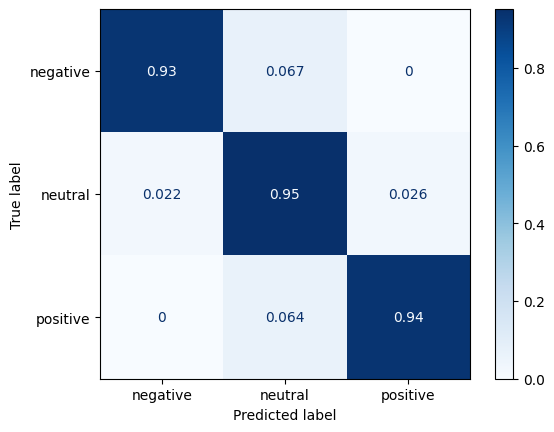

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "neutral", "positive"])
disp.plot(cmap=plt.cm.Blues)
plt.show()

# Testing the Trained Sentiment Model

The trained model is tested by providing individual hotel reviews and comparing its predictions with their actual sentiment labels.

The `test_prediction` function tokenizes a review, sends it to the same device as the trained model, and generates prediction probabilities for the three sentiment classes. The class with the highest probability is selected as the predicted sentiment, while the probability of that class is used as the model's confidence.

Instead of using generic sentences, eight real reviews are randomly selected from the test dataset. This provides a more representative evaluation because the selected reviews come from the same type of data used to train the model.

For each review, the **true sentiment, predicted sentiment, confidence score, and part of the review text** are displayed. A correct prediction is marked with a check mark, while an incorrect prediction is marked with a cross.

**Test Review → Tokenization → Model Prediction → Sentiment & Confidence → Compare with True Label**

In [20]:
def test_prediction(text, model, tokenizer, id2label):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=128)
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
        pred = torch.argmax(probs, dim=-1)
    return id2label[pred.item()], probs[0][pred].item(), probs[0].cpu().numpy()

# Pull 8 real examples from your own test set instead of generic product-review sentences —
# your vocabulary is narrow (~500-800 words) and templated, so generic English text
# ("waste of money") uses words the model never saw and won't be a fair test.
sample_idx = np.random.choice(len(X_test), 8, replace=False)
for i in sample_idx:
    text = X_test[i]
    true_label = id2label[y_test[i]]
    pred_label, conf, probs = test_prediction(text, model, tokenizer, id2label)
    match = "✓" if pred_label == true_label else "✗"
    print(f"{match} True: {true_label:8s} | Pred: {pred_label:8s} ({conf:.3f}) | {text[:70]}")

✓ True: positive | Pred: positive (0.988) | i was genuinely impressed that the in house cafe was worth waking up e
✗ True: negative | Pred: neutral  (0.952) | our stay in birmingham was fairly ordinary the location was fine nothi
✓ True: neutral  | Pred: neutral  (0.955) | the overall price was in line with similar hotels nothing more and not
✓ True: positive | Pred: positive (0.988) | we couldn t have asked for a better base while visiting liverpool that
✓ True: negative | Pred: negative (0.983) | our time in glasgow got off to a rocky start here that said the busine
✓ True: neutral  | Pred: neutral  (0.952) | the front desk team was fairly professional for what we paid meanwhile
✓ True: negative | Pred: negative (0.982) | we had high hopes for this hotel in belfast but were let down in addit
✓ True: positive | Pred: positive (0.988) | honestly the neighborhood was ideally situated meanwhile our arrival e


## Save the trained model

In [21]:
import json

# Save everything notebook 06 needs
trainer.save_model(str(MODEL_DIR / "distilbert_sentiment"))
tokenizer.save_pretrained(str(MODEL_DIR / "distilbert_sentiment"))

final_metrics = trainer.evaluate(eval_dataset=test_dataset)
run_info = {
    "metrics": final_metrics,
    "num_train_epochs": training_args.num_train_epochs,
    "per_device_train_batch_size": training_args.per_device_train_batch_size,
    "learning_rate": training_args.learning_rate,
}
with open(MODEL_DIR / "distilbert_run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

print("Saved model, tokenizer and run info to", MODEL_DIR)
print(final_metrics)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.248344,0.254301,3,0.941000,0.941290


Saved model, tokenizer and run info to ../models
{'eval_loss': 0.25430095195770264, 'eval_accuracy': 0.941, 'eval_f1': 0.9412901399975075}


In [23]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

MODEL_DIR = Path("/content/drive/MyDrive/your_project/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
